# Studio Proyek 3 — Fine-Tuning Transformer Pretrained untuk Klasifikasi Sentimen Bahasa Indonesia
**Mata Kuliah:** Pembelajaran Mendalam (IF25-40401) · Teknik Informatika, Institut Teknologi Sumatera

**Kelompok:** 22  
**Anggota:**

2. Ahmat Prayoga Sembiring — 123140053
3. Tengku Hafid Diraputra — 12314043

**Dataset:** SmSA (IndoNLU) · **Platform:** Google Colab / Kaggle (GPU T4) ·
Link Colab : https://colab.research.google.com/drive/1uueLQUHAkPlNAhsN6KsQgrNvulyU3kBn?usp=sharing



In [ ]:
%pip install -q transformers scikit-learn pandas matplotlib

In [ ]:
import os, gc, json, time, glob, hashlib, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import Dataset, DataLoader
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, get_linear_schedule_with_warmup, set_seed)
warnings.filterwarnings("ignore", category=FutureWarning)

# ====== PILIH MODE ======
MODE = "full"          # "smoke" = uji cepat (subset kecil, 1 epoch, 1 seed) | "full" = eksperimen penuh

DEVICE   = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP  = DEVICE == "cuda"          # mixed precision fp16 (T4 tidak mendukung bf16 dengan baik)
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU"
SESI_ID  = datetime.now().strftime("%Y%m%d-%H%M%S")
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
print(f"MODE={MODE} | device={DEVICE} | GPU={GPU_NAME} | torch={torch.__version__} | sesi={SESI_ID}")
if MODE == "full" and DEVICE == "cpu":
    raise RuntimeError("Mode full butuh GPU. Aktifkan GPU T4 dulu (Colab: Runtime > Change runtime type; Kaggle: Accelerator > GPU T4).")

MODE=full | device=cuda | GPU=Tesla T4 | torch=2.14.1+cu130 | sesi=20261117-071340


---
# SOAL 1 — Rancang Dulu Sebelum Ngoding
Sel di bawah adalah **sel Rancangan**: hipotesis (H1–H3), alasan desain, dan variabel terkendali. Isinya sudah berupa **draf** yang dibuat dari karakteristik dataset dan arsitektur model — *silakan dibaca, dipahami, dan disesuaikan dengan pemikiran kelompok sebelum menjalankan eksperimen pertama.* Mode `full` akan berhenti kalau ada bagian yang kosong atau masih berisi `TODO`/`ISI`.

**Fakta dataset yang mendasari rancangan** (dihitung dari berkas resmi SmSA di repo IndoNLU, sebelum pembersihan):
| Split | Jumlah | negative | neutral | positive |
|---|---|---|---|---|
| train | 11.000 | 3.436 | 1.148 | 6.416 |
| valid | 1.260 | 394 | 131 | 735 |
| test | 500 | 204 | 88 | 208 |

Kelas *neutral* hanya ±10% data latih → **F1 makro** dijadikan metrik utama (akurasi bisa menipu karena model yang selalu menebak "positive" sudah dapat ±58%).

In [ ]:
RANCANGAN = {
    "dataset": "SmSA (IndoNLU, Wilie dkk. 2020) — klasifikasi sentimen 3 kelas, Bahasa Indonesia",

    "alasan_dataset": (
        "SmSA dipilih (bukan IMDb) karena berbahasa Indonesia sehingga tiga backbone wajib "
        "(mBERT, DistilBERT-multilingual, IndoBERT) bisa dibandingkan secara adil tanpa faktor bahasa. "
        "Ukuran subset: memakai SELURUH data latih resmi hasil pembersihan (±10.9 ribu kalimat) tanpa subset, "
        "karena dengan max_length 128 dan batch 32 satu run ±3-5 menit di GPU T4 (perkiraan spesifikasi tugas), "
        "sehingga matriks 27 run tetap terjangkau; mengecilkan data hanya menambah variansi antar-seed tanpa "
        "penghematan berarti. Metrik utama F1 makro karena kelas neutral hanya ±10% data."
    ),

    "hipotesis": {
        "H1": (
            "Pada full fine-tuning, urutan F1 makro: IndoBERT > mBERT > DistilBERT-multilingual. "
            "Alasan: IndoBERT dipra-latih khusus pada korpus Indonesia dengan vocab Indonesia (50 ribu token), "
            "sedangkan mBERT membagi kapasitas & vocab ke >100 bahasa; DistilBERT adalah mBERT yang dikompresi "
            "(6 lapis) sehingga kapasitasnya paling kecil."
        ),
        "H2": (
            "DistilBERT-multilingual mempertahankan >=95% F1 makro mBERT (full FT) dengan latensi inferensi dan waktu "
            "latih jauh lebih rendah (kira-kira separuh, karena 6 lapis vs 12 lapis), tetapi penurunan jumlah "
            "parameter hanya sekitar 25% (±135 jt vs ±178 jt) karena matriks embedding multibahasa (±92 jt "
            "parameter) tidak ikut dikecilkan."
        ),
        "H3": (
            "Urutan F1 makro: full >= partial > linear probing pada tiap backbone. Linear probing paling murah "
            "(waktu latih & memori terendah, <1% parameter dilatih) tetapi tertinggal paling jauh (>5 poin F1 makro) "
            "karena representasi pra-latih belum disesuaikan dengan sentimen; partial freezing (separuh lapis awal "
            "dibekukan) berada dekat full (selisih <=2 poin) dengan biaya latih lebih rendah."
        ),
    },

    "alasan_desain": (
        "(1) Satu protokol identik untuk semua backbone (hiperparameter, seed, data) agar perbedaan hasil "
        "hanya berasal dari backbone/strategi. (2) Learning rate mengikuti strategi sesuai ketentuan: 3e-5 untuk "
        "full & partial (rentang 2e-5-5e-5), 2e-3 untuk probing (rentang 1e-3-5e-3) karena head baru dilatih dari nol "
        "sementara backbone beku. (3) Tidak ada early stopping/seleksi checkpoint: model epoch terakhir yang dievaluasi, "
        "jadi data validasi tidak dipakai untuk memilih model/hiperparameter dan tetap valid sebagai data uji "
        "internal; data test resmi dilaporkan sebagai pemeriksaan tambahan. (4) 3 seed beda per kombinasi dan "
        "hasil dilaporkan rata-rata ± simpangan baku. (5) Head replacement di semua run (num_labels=3). "
        "(6) Waktu inferensi dibandingkan dalam satu sesi GPU yang sama lewat benchmark latensi khusus."
    ),

    "variabel_terkendali": {
        "dataset_split": "split resmi SmSA; bersihkan duplikat, label bertentangan, dan kebocoran valid/test dari train",
        "max_length": 128,
        "batch_size": 32,
        "epochs": 3,
        "seeds": [42, 123, 2026],
        "optimizer": "AdamW (weight_decay=0.01, bias & LayerNorm tanpa decay), warmup 10% lalu linear decay, grad-clip 1.0",
        "precision": "fp16 mixed precision (autocast + GradScaler)",
        "lr_per_strategi": {"full": 3e-5, "partial": 3e-5, "probing": 2e-3},
        "partial_freezing": "bekukan embedding + separuh lapis awal (12 lapis -> 6; DistilBERT 6 lapis -> 3)",
        "linear_probing": "seluruh backbone beku; hanya head klasifikasi yang dilatih",
        "evaluasi": "checkpoint epoch terakhir; batch eval 64; latensi batch=1 (200 kalimat tetap, warmup 10)",
    },
}

MATRIKS_RANCANGAN = {   # backbone x strategi yang akan diisi (semua sel = 3 seed)
    "BERT (mBERT)":        ["probing", "partial", "full"],
    "DistilBERT (multi)":  ["probing", "partial", "full"],
    "IndoBERT":            ["probing", "partial", "full"],
}

def cek_rancangan(mode):
    # Menolak mode full kalau rancangan kosong / masih placeholder.
    def kosong(x):
        if isinstance(x, dict): return len(x) == 0 or any(kosong(v) for v in x.values())
        if isinstance(x, (list, tuple)): return len(x) == 0
        s = str(x).strip()
        return len(s) < 20 and not s.replace(".", "").isdigit() or "TODO" in s.upper() or s.upper().startswith("ISI")
    masalah = []
    for k in ["alasan_dataset", "alasan_desain"]:
        if kosong(RANCANGAN.get(k, "")): masalah.append(k)
    for h in ["H1", "H2", "H3"]:
        if kosong(RANCANGAN.get("hipotesis", {}).get(h, "")): masalah.append(f"hipotesis {h}")
    vt = RANCANGAN.get("variabel_terkendali", {})
    for k in ["max_length", "batch_size", "epochs", "seeds", "lr_per_strategi"]:
        if k not in vt or vt[k] in ("", None, [], {}): masalah.append(f"variabel_terkendali.{k}")
    if len(vt.get("seeds", [])) < 3: masalah.append("seeds (minimal 3)")
    if masalah and mode == "full":
        raise RuntimeError("Sel Rancangan belum lengkap -> " + ", ".join(masalah) + ". Lengkapi dulu sebelum eksperimen (Soal 1).")
    return masalah

print("Cek rancangan:", cek_rancangan(MODE) or "LENGKAP")

Cek rancangan: LENGKAP


In [ ]:
# Tabel matriks eksperimen (backbone x strategi) — ditampilkan SEBELUM ada kode eksperimen
V = RANCANGAN["variabel_terkendali"]
matriks = pd.DataFrame(
    {s: {b: f"{len(V['seeds'])} seed" if s in ss else "-" for b, ss in MATRIKS_RANCANGAN.items()}
     for s in ["probing", "partial", "full"]})
matriks.index.name = "backbone \\ strategi"
n_run = sum(len(v) for v in MATRIKS_RANCANGAN.values()) * len(V["seeds"])
print(f"Total run: {len(MATRIKS_RANCANGAN)} backbone x 3 strategi x {len(V['seeds'])} seed = {n_run} run\n")
print("Variabel terkendali:")
for k, v in V.items(): print(f"  - {k}: {v}")
matriks

Total run: 3 backbone x 3 strategi x 3 seed = 27 run

Variabel terkendali:
  - dataset_split: split resmi SmSA; bersihkan duplikat, label bertentangan, dan kebocoran valid/test dari train
  - max_length: 128
  - batch_size: 32
  - epochs: 3
  - seeds: [42, 123, 2026]
  - optimizer: AdamW (weight_decay=0.01, bias & LayerNorm tanpa decay), warmup 10% lalu linear decay, grad-clip 1.0
  - precision: fp16 mixed precision (autocast + GradScaler)
  - lr_per_strategi: {'full': 3e-05, 'partial': 3e-05, 'probing': 0.002}
  - partial_freezing: bekukan embedding + separuh lapis awal (12 lapis -> 6; DistilBERT 6 lapis -> 3)
  - linear_probing: seluruh backbone beku; hanya head klasifikasi yang dilatih
  - evaluasi: checkpoint epoch terakhir; batch eval 64; latensi batch=1 (200 kalimat tetap, warmup 10)


,probing,partial,full
backbone \ strategi,,,
BERT (mBERT),3 seed,3 seed,3 seed
DistilBERT (multi),3 seed,3 seed,3 seed
IndoBERT,3 seed,3 seed,3 seed


---
# Konfigurasi (diturunkan dari sel Rancangan)
Semua nilai diambil dari `RANCANGAN["variabel_terkendali"]` supaya rancangan dan kode tidak bisa berbeda. `KODE` adalah hash konfigurasi: kalau ada variabel yang diubah, nama berkas hasil ikut berubah sehingga hasil dari konfigurasi berbeda **tidak tercampur**.

In [ ]:
SEEDS, MAX_LEN, BATCH, EPOCHS = V["seeds"], V["max_length"], V["batch_size"], V["epochs"]
LR = V["lr_per_strategi"]
LABELS   = ["negative", "neutral", "positive"]
LABEL2ID = {l: i for i, l in enumerate(LABELS)}
ID2LABEL = {i: l for l, i in LABEL2ID.items()}
EVAL_BS  = 64
N_LAT, WARMUP_LAT = 200, 10

BACKBONES = {   # semua model pra-latih menyertakan Bahasa Indonesia (adil untuk SmSA)
    "mbert":       dict(nama="bert-base-multilingual-cased",       label="BERT (mBERT)"),
    "distilmbert": dict(nama="distilbert-base-multilingual-cased", label="DistilBERT (multi)"),
    "indobert":    dict(nama="indobenchmark/indobert-base-p1",      label="IndoBERT"),
    "xlmr":        dict(nama="xlm-roberta-base",                    label="XLM-R (opsional)"),
}
PAKAI_XLMR = False                      # True = tambah XLM-R (nilai plus; +9 run, memori lebih besar)
STRATEGI   = ["probing", "partial", "full"]
AKTIF      = [b for b in BACKBONES if b != "xlmr" or PAKAI_XLMR]

# subset hanya untuk mode smoke
if MODE == "smoke":
    SEEDS, EPOCHS = SEEDS[:1], 1
    N_SUB = dict(train=480, valid=160, test=96)
else:
    N_SUB = None

_cfg = dict(V=V, backbones={k: v["nama"] for k, v in BACKBONES.items()}, versi_pembersihan=1)
KODE  = "smoke" if MODE == "smoke" else hashlib.md5(json.dumps(_cfg, sort_keys=True, default=str).encode()).hexdigest()[:6]
HASIL = f"hasil_smsa_{KODE}.csv"
REKAP = f"rekap_agregat_smsa_{KODE}.csv"
LATEN = f"latensi_smsa_{KODE}.csv"
print("KODE konfigurasi:", KODE, "\n ", HASIL, "\n ", REKAP, "\n ", LATEN)

KODE konfigurasi: a00952 
  hasil_smsa_a00952.csv 
  rekap_agregat_smsa_a00952.csv 
  latensi_smsa_a00952.csv


---
# Data: SmSA resmi + pembersihan
Berkas diambil langsung dari repo IndoNLU (split resmi train/valid/test, tanpa header). Pembersihan: (1) teks berlabel **bertentangan** dibuang, (2) **duplikat** dibuang, (3) teks valid/test yang **ada di data latih** dibuang (kebocoran).

In [ ]:
RAW = os.environ.get("SMSA_DIR", "https://raw.githubusercontent.com/IndoNLP/indonlu/master/dataset/smsa_doc-sentiment-prosa")

def baca(fname):
    d = pd.read_csv(f"{RAW}/{fname}", sep="\t", header=None, names=["text", "label"], quoting=3, keep_default_na=False)
    d["text"] = d["text"].astype(str).str.strip()
    return d[(d["text"].str.len() > 0) & d["label"].isin(LABELS)].reset_index(drop=True)

def buang_konflik_dan_duplikat(d):
    nun = d.groupby("text")["label"].transform("nunique")
    n_konflik = int((nun > 1).sum())
    d = d[nun == 1]
    n_dup = int(d.duplicated("text").sum())
    return d.drop_duplicates("text"), n_konflik, n_dup

def bersihkan(tr, va, te):
    lap = []
    tr0, va0, te0 = len(tr), len(va), len(te)
    tr, k, dp = buang_konflik_dan_duplikat(tr); lap.append(("train", tr0, k, dp, 0, len(tr)))
    va, k, dp = buang_konflik_dan_duplikat(va)
    n_leak = int(va["text"].isin(set(tr["text"])).sum()); va = va[~va["text"].isin(set(tr["text"]))]
    lap.append(("valid", va0, k, dp, n_leak, len(va)))
    te, k, dp = buang_konflik_dan_duplikat(te)
    bocor = set(tr["text"]) | set(va["text"])
    n_leak = int(te["text"].isin(bocor).sum()); te = te[~te["text"].isin(bocor)]
    lap.append(("test", te0, k, dp, n_leak, len(te)))
    laporan = pd.DataFrame(lap, columns=["split", "awal", "label_konflik", "duplikat", "bocor_ke_train", "akhir"])
    return tr.reset_index(drop=True), va.reset_index(drop=True), te.reset_index(drop=True), laporan

train_df, valid_df, test_df, laporan_bersih = bersihkan(
    baca("train_preprocess.tsv"), baca("valid_preprocess.tsv"), baca("test_preprocess.tsv"))
if N_SUB:   # smoke: subset acak tetap
    train_df = train_df.sample(N_SUB["train"], random_state=0).reset_index(drop=True)
    valid_df = valid_df.sample(N_SUB["valid"], random_state=0).reset_index(drop=True)
    test_df  = test_df.sample(N_SUB["test"],  random_state=0).reset_index(drop=True)

display(laporan_bersih)
dist = pd.DataFrame({n: d["label"].value_counts().reindex(LABELS) for n, d in
                     [("train", train_df), ("valid", valid_df), ("test", test_df)]})
display(dist.assign(**{"train_%": (dist["train"] / dist["train"].sum() * 100).round(1)}))
print("Baseline 'selalu positive' pada valid: akurasi=%.3f, F1 makro=%.3f" % (
    (valid_df.label == "positive").mean(),
    f1_score(valid_df.label.map(LABEL2ID), [2] * len(valid_df), average="macro", zero_division=0)))

,split,awal,label_konflik,duplikat,bocor_ke_train,akhir
0,train,11000,0,67,0,10933
1,valid,1260,0,0,14,1246
2,test,500,0,0,0,500


,train,valid,test,train_%
label,,,,
negative,3412,389,204,31.2
neutral,1138,129,88,10.4
positive,6383,728,208,58.4


Baseline 'selalu positive' pada valid: akurasi=0.584, F1 makro=0.246


In [ ]:
# ---- Tokenisasi per backbone (tokenizer tiap model berbeda) + data loader ----
class TeksDS(Dataset):
    def __init__(self, items, labels=None): self.items, self.labels = items, labels
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        x = dict(self.items[i])
        if self.labels is not None: x["labels"] = int(self.labels[i])
        return x

_cache_data = {}
def siapkan_data(bk):
    if bk in _cache_data: return _cache_data[bk]
    tok = AutoTokenizer.from_pretrained(BACKBONES[bk]["nama"])
    out = dict(tok=tok, collator=DataCollatorWithPadding(tok))
    for nama, df in [("train", train_df), ("valid", valid_df), ("test", test_df)]:
        enc = tok(df["text"].tolist(), truncation=True, max_length=MAX_LEN)
        items = [{k: enc[k][i] for k in enc.keys()} for i in range(len(df))]
        out[nama] = dict(items=items, y=df["label"].map(LABEL2ID).values)
        out[nama + "_dipotong"] = float(np.mean([len(x["input_ids"]) >= MAX_LEN for x in items]))
    _cache_data[bk] = out
    return out

# Bukti untuk memilih max_length: berapa % kalimat terpotong tiap tokenizer?
print(f"max_length = {MAX_LEN}. Persentase kalimat latih yang terpotong:")
for bk in AKTIF:
    d = siapkan_data(bk)
    panjang = np.array([len(x["input_ids"]) for x in d["train"]["items"]])
    print(f"  {BACKBONES[bk]['label']:<20s} terpotong={d['train_dipotong']*100:5.2f}% | median={np.median(panjang):.0f} token | p95={np.percentile(panjang,95):.0f} token")

max_length = 128. Persentase kalimat latih yang terpotong:


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

  BERT (mBERT)         terpotong= 0.17% | median=44 token | p95=104 token


... (6 outputs left out)

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

  IndoBERT             terpotong= 0.01% | median=33 token | p95=79 token


---
# SOAL 3 — Strategi fine-tuning (kode freezing terlihat jelas di sini)
* **Head replacement (semua run):** `AutoModelForSequenceClassification.from_pretrained(..., num_labels=3)` membuang head asli dan membuat head klasifikasi baru (acak, diinisialisasi setelah `set_seed`) sesuai 3 label.
* **Full fine-tuning:** semua parameter `requires_grad=True`.
* **Partial freezing:** embedding + separuh lapis awal `requires_grad=False` (12→6 lapis; DistilBERT 6→3).
* **Linear probing:** seluruh `base_model` beku; hanya head yang dilatih.

> Catatan adil-tidaknya: untuk DistilBERT dan XLM-R, "head" di HuggingFace memuat satu lapis `Linear` tambahan sebelum classifier (`pre_classifier` / `dense`), jadi parameter yang dilatih pada probing sedikit lebih banyak daripada BERT (yang hanya 768×3+3). Ini ikut tercatat di kolom `params_trainable`.

In [ ]:
def muat_model(bk, set_seed_dulu=None):
    # HEAD REPLACEMENT: num_labels=3 -> head baru (acak) menggantikan head pra-latih.
    if set_seed_dulu is not None: set_seed(set_seed_dulu)
    model, info = AutoModelForSequenceClassification.from_pretrained(
        BACKBONES[bk]["nama"], num_labels=len(LABELS), id2label=ID2LABEL, label2id=LABEL2ID,
        output_loading_info=True)
    return model, info

def ambil_lapis(model):
    base = model.base_model
    if hasattr(base, "transformer"): return list(base.transformer.layer)   # DistilBERT
    return list(base.encoder.layer)                                         # BERT / RoBERTa / XLM-R

def atur_strategi(model, strategi):
    # Semua parameter dibuka dulu, lalu bagian tertentu DIBEKUKAN sesuai strategi.
    for p in model.parameters(): p.requires_grad = True
    if strategi == "full":
        pass
    elif strategi == "probing":
        for p in model.base_model.parameters(): p.requires_grad = False       # backbone beku, head tetap dilatih
    elif strategi == "partial":
        lapis = ambil_lapis(model)
        n_beku = len(lapis) // 2                                              # 12 -> 6 ; DistilBERT 6 -> 3
        for p in model.base_model.embeddings.parameters(): p.requires_grad = False
        for l in lapis[:n_beku]:
            for p in l.parameters(): p.requires_grad = False
    else:
        raise ValueError(strategi)
    return model

def hitung_param(model):
    tot = sum(p.numel() for p in model.parameters())
    lat = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return tot, lat

def ringkasan_pembekuan(model):
    # Tabel status beku/dilatih per blok -> bukti freezing di output notebook.
    base, baris = model.base_model, []
    def st(mod):
        ps = list(mod.parameters()); n = sum(p.numel() for p in ps)
        return ("DILATIH" if all(p.requires_grad for p in ps) else "BEKU" if not any(p.requires_grad for p in ps) else "SEBAGIAN"), n
    baris.append(("embeddings", *st(base.embeddings)))
    for i, l in enumerate(ambil_lapis(model)): baris.append((f"lapis {i}", *st(l)))
    if getattr(base, "pooler", None) is not None: baris.append(("pooler", *st(base.pooler)))
    ids = {id(p) for p in base.parameters()}   # sisanya = head baru
    sisa = [p for p in model.parameters() if id(p) not in ids]
    n_h = sum(p.numel() for p in sisa)
    baris.append(("head (baru)", "DILATIH" if all(p.requires_grad for p in sisa) else "BEKU", n_h))
    return pd.DataFrame(baris, columns=["blok", "status", "jumlah_param"])

def periksa_strategi(backbones):
    # Cek urutan parameter dilatih: probing < partial < full (syarat spesifikasi) untuk tiap backbone.
    baris = []
    for bk in backbones:
        model, info = muat_model(bk)
        print(f"[{BACKBONES[bk]['label']}] bobot baru (head, acak): {sorted(info['missing_keys'])}")
        for s in STRATEGI:
            atur_strategi(model, s); tot, lat = hitung_param(model)
            baris.append(dict(backbone=bk, strategi=s, params_total=tot, params_trainable=lat, persen_dilatih=round(100 * lat / tot, 2)))
        del model; gc.collect()
    df = pd.DataFrame(baris)
    for bk in backbones:
        t = df[df.backbone == bk].set_index("strategi")["params_trainable"]
        assert t["probing"] < t["partial"] < t["full"], f"Urutan parameter salah untuk {bk}: {t.to_dict()}"
    print("OK: parameter dilatih berurutan probing < partial < full pada semua backbone.")
    return df

# Contoh bukti freezing pada satu model (tanpa pelatihan):
_m, _ = muat_model("indobert")
atur_strategi(_m, "partial")
print("Strategi PARTIAL pada", BACKBONES["indobert"]["label"])
display(ringkasan_pembekuan(_m)); del _m; gc.collect()

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Strategi PARTIAL pada IndoBERT


,blok,status,jumlah_param
0,embeddings,BEKU,38796288
1,lapis 0,BEKU,7087872
2,lapis 1,BEKU,7087872
3,lapis 2,BEKU,7087872
4,lapis 3,BEKU,7087872
5,lapis 4,BEKU,7087872
6,lapis 5,BEKU,7087872
7,lapis 6,DILATIH,7087872
8,lapis 7,DILATIH,7087872
9,lapis 8,DILATIH,7087872


1698

In [ ]:
# Pemeriksaan sebelum eksperimen: urutan jumlah parameter dilatih (probing < partial < full)
tabel_param = periksa_strategi(AKTIF)
tabel_param

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (7 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[IndoBERT] bobot baru (head, acak): ['classifier.bias', 'classifier.weight']
OK: parameter dilatih berurutan probing < partial < full pada semua backbone.


,backbone,strategi,params_total,params_trainable,persen_dilatih
0,mbert,probing,177855747,2307,0.00
1,mbert,partial,177855747,43120131,24.24
2,mbert,full,177855747,177855747,100.00
3,distilmbert,probing,135326979,592899,0.44
4,distilmbert,partial,135326979,21856515,16.15
5,distilmbert,full,135326979,135326979,100.00
6,indobert,probing,124443651,2307,0.00
7,indobert,partial,124443651,43120131,34.65
8,indobert,full,124443651,124443651,100.00


---
# Fungsi pelatihan & evaluasi (satu run = satu backbone × strategi × seed)
Metrik otomatis per run: akurasi & F1 makro (valid dan test), F1 per kelas, waktu latih, latensi inferensi (ms/kalimat, batch=1), parameter total & dilatih, memori puncak GPU.

In [ ]:
def bersihkan_gpu():
    gc.collect()
    if DEVICE == "cuda": torch.cuda.empty_cache()

def sinkron():
    if DEVICE == "cuda": torch.cuda.synchronize()

@torch.no_grad()
def prediksi(model, ds, collator):
    model.eval()
    loader = DataLoader(ds, batch_size=EVAL_BS, shuffle=False, collate_fn=collator)
    hasil = []
    for b in loader:
        b = {k: v.to(DEVICE) for k, v in b.items() if k != "labels"}
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            hasil.append(model(**b).logits.argmax(-1).cpu())
    return torch.cat(hasil).numpy()

@torch.no_grad()
def ukur_latensi(model, items, collator, n=N_LAT, warmup=WARMUP_LAT):
    # Latensi batch=1 (skenario real-time), rata-rata ms/kalimat; tokenisasi tidak dihitung.
    model.eval()
    n = min(n, len(items))
    batches = [collator([items[i]]) for i in range(n)]
    def satu(b):
        b = {k: v.to(DEVICE) for k, v in b.items() if k != "labels"}
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            model(**b)
    for b in batches[:warmup]: satu(b)
    sinkron(); t0 = time.perf_counter()
    for b in batches: satu(b)
    sinkron()
    return (time.perf_counter() - t0) / n * 1000

def metrik(y, p):
    f = f1_score(y, p, average=None, labels=[0, 1, 2], zero_division=0)
    return dict(acc=accuracy_score(y, p), f1_macro=f1_score(y, p, average="macro", zero_division=0),
                f1_neg=f[0], f1_neu=f[1], f1_pos=f[2])

def jalankan_satu(bk, strategi, seed):
    d = siapkan_data(bk)
    bersihkan_gpu()
    if DEVICE == "cuda": torch.cuda.reset_peak_memory_stats()
    model, _ = muat_model(bk, set_seed_dulu=seed)                 # set_seed -> head baru ter-inisialisasi deterministik
    atur_strategi(model, strategi)
    model.to(DEVICE)
    tot, lat = hitung_param(model)

    g = torch.Generator().manual_seed(seed)                       # urutan shuffle deterministik per seed
    loader = DataLoader(TeksDS(d["train"]["items"], d["train"]["y"]), batch_size=BATCH, shuffle=True,
                        collate_fn=d["collator"], generator=g)
    named = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
    tanpa_decay = lambda n: "bias" in n or "LayerNorm" in n or "layer_norm" in n
    opt = torch.optim.AdamW([
        dict(params=[p for n, p in named if not tanpa_decay(n)], weight_decay=0.01),
        dict(params=[p for n, p in named if tanpa_decay(n)],     weight_decay=0.0)], lr=LR[strategi])
    total_step = len(loader) * EPOCHS
    sch = get_linear_schedule_with_warmup(opt, int(0.1 * total_step), total_step)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    sinkron(); t0 = time.perf_counter(); loss_ep = []
    for ep in range(EPOCHS):
        model.train(); tot_loss, n = 0.0, 0
        for b in loader:
            b = {k: v.to(DEVICE) for k, v in b.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                loss = model(**b).loss
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_([p for _, p in named], 1.0)
            scaler.step(opt); scaler.update(); sch.step()
            tot_loss += loss.item() * len(b["labels"]); n += len(b["labels"])
        loss_ep.append(tot_loss / n)
    sinkron(); waktu_latih = time.perf_counter() - t0
    mem = torch.cuda.max_memory_allocated() / 2**20 if DEVICE == "cuda" else float("nan")

    # Evaluasi: checkpoint epoch terakhir (tanpa seleksi model)
    mv = metrik(d["valid"]["y"], prediksi(model, TeksDS(d["valid"]["items"]), d["collator"]))
    mt = metrik(d["test"]["y"],  prediksi(model, TeksDS(d["test"]["items"]),  d["collator"]))
    lat_ms = ukur_latensi(model, d["valid"]["items"], d["collator"])

    baris = dict(dataset="smsa", kode=KODE, backbone=bk, model=BACKBONES[bk]["nama"], strategi=strategi, seed=seed,
                 lr=LR[strategi], epochs=EPOCHS, batch_size=BATCH, max_length=MAX_LEN,
                 params_total=tot, params_trainable=lat, persen_dilatih=100 * lat / tot,
                 train_time_s=waktu_latih, latency_ms=lat_ms, peak_mem_mb=mem, final_train_loss=loss_ep[-1],
                 val_acc=mv["acc"], val_f1_macro=mv["f1_macro"], val_f1_neg=mv["f1_neg"], val_f1_neu=mv["f1_neu"], val_f1_pos=mv["f1_pos"],
                 test_acc=mt["acc"], test_f1_macro=mt["f1_macro"], gpu=GPU_NAME, sesi=SESI_ID,
                 waktu_selesai=datetime.now().isoformat(timespec="seconds"))
    del model, opt, sch, scaler, loader; bersihkan_gpu()
    return baris

---
# Eksekusi matriks eksperimen
Hasil disimpan ke CSV **setiap selesai satu run**, dan run yang sudah ada dilewati (aman kalau sesi Colab/Kaggle putus — jalankan ulang sel ini saja).
Untuk membagi kerja, ubah `RUN_BACKBONES` / `RUN_SEEDS` dan beri `SUFIKS_ANGGOTA` unik (mis. `"_a1"`) supaya berkas tiap anggota terpisah.

In [ ]:
RUN_BACKBONES  = AKTIF           # contoh bagi tugas: ["mbert"]  |  ["distilmbert"]  |  ["indobert"]
RUN_SEEDS      = SEEDS           # contoh: [42] (jangan kurangi bila ingin memenuhi minimal 3 seed per kombinasi)
SUFIKS_ANGGOTA = ""              # contoh: "_a1"  -> hasil_smsa_<kode>_a1.csv

FILE_HASIL = HASIL.replace(".csv", f"{SUFIKS_ANGGOTA}.csv")
KUNCI = ["backbone", "strategi", "seed"]

def muat_hasil():
    return pd.read_csv(FILE_HASIL) if os.path.exists(FILE_HASIL) else pd.DataFrame()

def jalankan_matriks():
    cek_rancangan(MODE)      # gerbang Soal 1: mode full menolak jalan bila Rancangan kosong
    df = muat_hasil()
    antrean = [(b, s, sd) for b in RUN_BACKBONES for s in STRATEGI for sd in RUN_SEEDS]
    selesai = set(map(tuple, df[KUNCI].values.tolist())) if len(df) else set()
    sisa = [a for a in antrean if a not in selesai]
    print(f"Antrean: {len(antrean)} run | sudah selesai: {len(antrean) - len(sisa)} | akan dijalankan: {len(sisa)}")
    t_awal = time.time()
    for i, (b, s, sd) in enumerate(sisa, 1):
        t0 = time.time()
        baris = jalankan_satu(b, s, sd)
        df = pd.concat([df, pd.DataFrame([baris])], ignore_index=True)
        df.to_csv(FILE_HASIL, index=False)
        print(f"[{i}/{len(sisa)}] {b:<12s} {s:<8s} seed={sd:<5d} | F1m val={baris['val_f1_macro']:.4f} acc={baris['val_acc']:.4f} "
              f"| latih={baris['train_time_s']:.0f}s | {time.time()-t0:.0f}s total | tersimpan -> {FILE_HASIL}")
    print(f"Selesai dalam {(time.time()-t_awal)/60:.1f} menit.")
    return df

hasil = jalankan_matriks()
hasil.tail()

Antrean: 27 run | sudah selesai: 0 | akan dijalankan: 27


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[1/27] mbert        probing  seed=42    | F1m val=0.6714 acc=0.7705 | latih=62s | 70s total | tersimpan -> hasil_smsa_a00952.csv


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (82 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[27/27] indobert     full     seed=2026  | F1m val=0.9216 acc=0.9446 | latih=174s | 181s total | tersimpan -> hasil_smsa_a00952.csv
Selesai dalam 51.3 menit.


,dataset,kode,backbone,model,strategi,seed,lr,epochs,batch_size,max_length,...,val_acc,val_f1_macro,val_f1_neg,val_f1_neu,val_f1_pos,test_acc,test_f1_macro,gpu,sesi,waktu_selesai
22,smsa,a00952,indobert,indobenchmark/indobert-base-p1,partial,123,0.00003,3,32,128,...,0.935795,0.906693,0.922126,0.838174,0.959778,0.916,0.889107,Tesla T4,20261117-071340,2026-11-17T07:55:08
23,smsa,a00952,indobert,indobenchmark/indobert-base-p1,partial,2026,0.00003,3,32,128,...,0.935795,0.906231,0.923463,0.835341,0.959889,0.926,0.902793,Tesla T4,20261117-071340,2026-11-17T07:56:57
24,smsa,a00952,indobert,indobenchmark/indobert-base-p1,full,42,0.00003,3,32,128,...,0.938202,0.914345,0.925599,0.858268,0.959170,0.914,0.890930,Tesla T4,20261117-071340,2026-11-17T07:59:58
25,smsa,a00952,indobert,indobenchmark/indobert-base-p1,full,123,0.00003,3,32,128,...,0.944623,0.917151,0.935687,0.850202,0.965565,0.928,0.904721,Tesla T4,20261117-071340,2026-11-17T08:02:59
26,smsa,a00952,indobert,indobenchmark/indobert-base-p1,full,2026,0.00003,3,32,128,...,0.944623,0.921631,0.933333,0.867470,0.964088,0.920,0.893702,Tesla T4,20261117-071340,2026-11-17T08:06:00


In [ ]:
# (Opsional tapi disarankan) Uji reprodusibilitas: set_seed() + kode yang sama harus memberi hasil konsisten.
# Memakai kombinasi tercepat; hasil TIDAK disimpan ke CSV.
def uji_reprodusibilitas(bk=None, strategi="probing", seed=SEEDS[0], toleransi=1e-3):
    bk = bk or ("distilmbert" if "distilmbert" in AKTIF else AKTIF[0])
    a, b = jalankan_satu(bk, strategi, seed), jalankan_satu(bk, strategi, seed)
    selisih = abs(a["val_f1_macro"] - b["val_f1_macro"])
    print(f"Run 1 F1m={a['val_f1_macro']:.5f} | Run 2 F1m={b['val_f1_macro']:.5f} | selisih={selisih:.5f} ->",
          "KONSISTEN" if selisih <= toleransi else "BEDA (cek sumber nondeterminisme GPU)")
uji_reprodusibilitas()

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Run 1 F1m=0.75013 | Run 2 F1m=0.75013 | selisih=0.00000 -> KONSISTEN


In [ ]:
# Benchmark latensi: SEMUA backbone diukur dalam SATU sesi GPU yang sama (syarat perbandingan waktu inferensi).
# Latensi tidak bergantung pada strategi (arsitektur sama), jadi diukur sekali per backbone, 5 pengulangan.
def benchmark_latensi(backbones, ulang=5):
    baris = []
    for bk in backbones:
        d = siapkan_data(bk); model, _ = muat_model(bk, set_seed_dulu=0); model.to(DEVICE)
        tot, _ = hitung_param(model)
        ls = [ukur_latensi(model, d["valid"]["items"], d["collator"]) for _ in range(ulang)]
        baris.append(dict(backbone=bk, params_total=tot, latensi_ms_mean=np.mean(ls), latensi_ms_std=np.std(ls, ddof=1), gpu=GPU_NAME, sesi=SESI_ID))
        del model; bersihkan_gpu()
    df = pd.DataFrame(baris); df.to_csv(LATEN, index=False)
    return df
lat_bench = benchmark_latensi(AKTIF)
lat_bench

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,backbone,params_total,latensi_ms_mean,latensi_ms_std,gpu,sesi
0,mbert,177855747,13.885824,1.829918,Tesla T4,20261117-071340
1,distilmbert,135326979,6.569006,0.035313,Tesla T4,20261117-071340
2,indobert,124443651,13.517675,1.016263,Tesla T4,20261117-071340


---
# Gabung hasil antar-anggota (lewati kalau satu orang menjalankan semua)
Unggah berkas `hasil_smsa_<KODE>*.csv` milik anggota lain ke folder kerja yang sama, lalu jalankan sel ini. Duplikat (backbone, strategi, seed) otomatis dibuang. **Pastikan `KODE` sama** — kalau beda berarti konfigurasi beda dan jangan digabung. Latensi per-run dari sesi berbeda tidak dibandingkan langsung; gunakan benchmark latensi (sel di atas) yang dijalankan dalam satu sesi.

In [ ]:
def gabung_hasil():
    files = sorted(glob.glob(f"hasil_smsa_{KODE}*.csv"))
    dfs = [pd.read_csv(f) for f in files]
    assert dfs, "Tidak ada berkas hasil ditemukan."
    df = pd.concat(dfs, ignore_index=True).drop_duplicates(KUNCI, keep="last")
    assert (df["kode"] == KODE).all(), "Ada hasil dengan KODE berbeda -> konfigurasi tidak sama, jangan digabung!"
    df.to_csv(HASIL, index=False)
    print(f"Digabung dari {files} -> {HASIL}: {len(df)} run")
    return df
hasil = gabung_hasil()

Digabung dari ['hasil_smsa_a00952.csv'] -> hasil_smsa_a00952.csv: 27 run


---
# Analisis hasil
Semua angka dilaporkan **rata-rata ± simpangan baku antar-seed** (n = jumlah seed). Dengan hanya 3 seed, simpangan baku bersifat indikatif — selisih yang lebih kecil dari simpangan baku jangan dianggap perbedaan nyata.

In [ ]:
METRIK = ["val_acc", "val_f1_macro", "test_acc", "test_f1_macro", "train_time_s", "latency_ms",
          "params_total", "params_trainable", "peak_mem_mb"]
URUT_B = {b: i for i, b in enumerate(BACKBONES)}
URUT_S = {s: i for i, s in enumerate(STRATEGI)}

def rekap(df):
    g = df.groupby(["backbone", "strategi"])
    out = pd.concat([g.size().rename("n_seed"), g[METRIK].mean().add_suffix("_mean"), g[METRIK].std(ddof=1).add_suffix("_std")], axis=1).reset_index()
    out["_o"] = out["backbone"].map(URUT_B) * 10 + out["strategi"].map(URUT_S)
    return out.sort_values("_o").drop(columns="_o").reset_index(drop=True)

hasil = pd.read_csv(HASIL) if os.path.exists(HASIL) else muat_hasil()
agg = rekap(hasil)
# gabungkan latensi benchmark (satu sesi) bila ada
if os.path.exists(LATEN):
    lb = pd.read_csv(LATEN).set_index("backbone")
    agg["latensi_bench_ms"] = agg["backbone"].map(lb["latensi_ms_mean"])
    agg["latensi_bench_std"] = agg["backbone"].map(lb["latensi_ms_std"])
agg.to_csv(REKAP, index=False)

def pm(m, s, f="{:.4f}"): return (f.format(m) + " ± " + f.format(s)) if pd.notna(s) else f.format(m)
tampil = pd.DataFrame({
    "Backbone": agg["backbone"].map(lambda b: BACKBONES[b]["label"]), "Strategi": agg["strategi"], "n seed": agg["n_seed"],
    "Akurasi (valid)":   [pm(m, s) for m, s in zip(agg.val_acc_mean, agg.val_acc_std)],
    "F1 makro (valid)":  [pm(m, s) for m, s in zip(agg.val_f1_macro_mean, agg.val_f1_macro_std)],
    "F1 makro (test)":   [pm(m, s) for m, s in zip(agg.test_f1_macro_mean, agg.test_f1_macro_std)],
    "Waktu latih (s)":   [pm(m, s, "{:.0f}") for m, s in zip(agg.train_time_s_mean, agg.train_time_s_std)],
    "Latensi (ms/kal.)": [pm(m, s, "{:.2f}") for m, s in zip(agg.get("latensi_bench_ms", agg.latency_ms_mean), agg.get("latensi_bench_std", agg.latency_ms_std))],
    "Param total (jt)":  (agg.params_total_mean / 1e6).round(1),
    "Param dilatih (jt)": (agg.params_trainable_mean / 1e6).round(2),
    "Mem puncak (MB)":   agg.peak_mem_mb_mean.round(0),
})
if hasil["sesi"].nunique() > 1 and not os.path.exists(LATEN):
    print("PERINGATAN: hasil berasal dari >1 sesi; latensi antar-sesi tidak sebanding. Jalankan sel benchmark latensi.")
print(f"Disimpan: {HASIL} ({len(hasil)} run) | {REKAP}")
display(tampil)

Disimpan: hasil_smsa_a00952.csv (27 run) | rekap_agregat_smsa_a00952.csv


,Backbone,Strategi,n seed,Akurasi (valid),F1 makro (valid),F1 makro (test),Waktu latih (s),Latensi (ms/kal.),Param total (jt),Param dilatih (jt),Mem puncak (MB)
0,BERT (mBERT),probing,3,0.7681 ± 0.0029,0.6604 ± 0.0096,0.4543 ± 0.0034,61 ± 1,13.89 ± 1.83,177.9,0.00,785.0
1,BERT (mBERT),partial,3,0.8799 ± 0.0052,0.8401 ± 0.0053,0.7534 ± 0.0126,124 ± 0,13.89 ± 1.83,177.9,43.12,2137.0
2,BERT (mBERT),full,3,0.9141 ± 0.0028,0.8783 ± 0.0020,0.8143 ± 0.0073,231 ± 0,13.89 ± 1.83,177.9,177.86,4584.0
3,DistilBERT (multi),probing,3,0.8154 ± 0.0008,0.7529 ± 0.0027,0.5386 ± 0.0080,31 ± 0,6.57 ± 0.04,135.3,0.59,624.0
4,DistilBERT (multi),partial,3,0.8590 ± 0.0040,0.8080 ± 0.0070,0.7041 ± 0.0154,66 ± 5,6.57 ± 0.04,135.3,21.86,1274.0
5,DistilBERT (multi),full,3,0.9090 ± 0.0005,0.8688 ± 0.0019,0.7966 ± 0.0105,132 ± 0,6.57 ± 0.04,135.3,135.33,3025.0
6,IndoBERT,probing,3,0.8922 ± 0.0017,0.8570 ± 0.0029,0.7688 ± 0.0154,47 ± 0,13.52 ± 1.02,124.4,0.00,582.0
7,IndoBERT,partial,3,0.9347 ± 0.0019,0.9058 ± 0.0012,0.8941 ± 0.0075,101 ± 0,13.52 ± 1.02,124.4,43.12,1915.0
8,IndoBERT,full,3,0.9425 ± 0.0037,0.9177 ± 0.0037,0.8965 ± 0.0073,174 ± 0,13.52 ± 1.02,124.4,124.44,3730.0


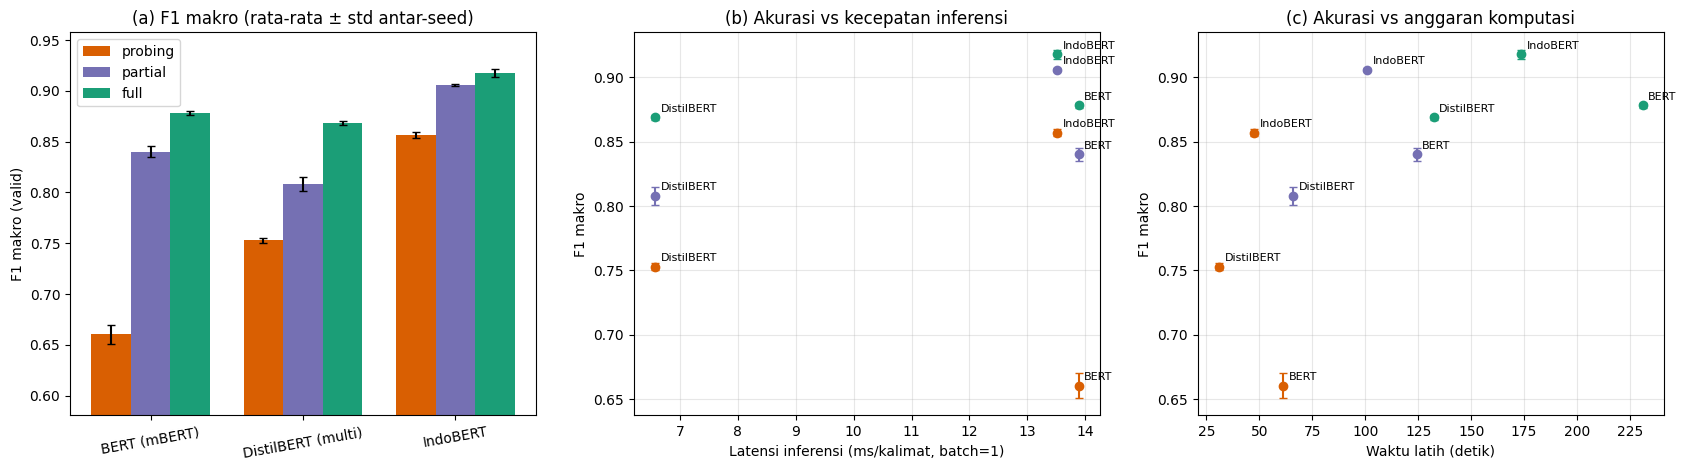

Disimpan: grafik_studio3_a00952.png


In [ ]:
# ---- Grafik: (a) F1 makro ± std, (b) F1 vs latensi, (c) F1 vs waktu latih ----
warna = {"probing": "#d95f02", "partial": "#7570b3", "full": "#1b9e77"}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
bks = [b for b in BACKBONES if b in agg.backbone.values]; w = 0.26
for j, s in enumerate(STRATEGI):
    sub = agg[agg.strategi == s].set_index("backbone").reindex(bks)
    ax[0].bar(np.arange(len(bks)) + (j - 1) * w, sub.val_f1_macro_mean, w, yerr=sub.val_f1_macro_std.fillna(0),
              capsize=3, label=s, color=warna[s])
ax[0].set_xticks(range(len(bks))); ax[0].set_xticklabels([BACKBONES[b]["label"] for b in bks], rotation=10)
ax[0].set_ylabel("F1 makro (valid)"); ax[0].set_title("(a) F1 makro (rata-rata ± std antar-seed)")
ax[0].set_ylim(max(0, agg.val_f1_macro_mean.min() - 0.08), min(1, agg.val_f1_macro_mean.max() + 0.04)); ax[0].legend()
lat_kol = "latensi_bench_ms" if "latensi_bench_ms" in agg else "latency_ms_mean"
for _, r in agg.iterrows():
    ax[1].errorbar(r[lat_kol], r.val_f1_macro_mean, yerr=0 if pd.isna(r.val_f1_macro_std) else r.val_f1_macro_std, fmt="o", color=warna[r.strategi], capsize=3)
    ax[1].annotate(BACKBONES[r.backbone]["label"].split()[0], (r[lat_kol], r.val_f1_macro_mean), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax[2].errorbar(r.train_time_s_mean, r.val_f1_macro_mean, yerr=0 if pd.isna(r.val_f1_macro_std) else r.val_f1_macro_std, fmt="o", color=warna[r.strategi], capsize=3)
    ax[2].annotate(BACKBONES[r.backbone]["label"].split()[0], (r.train_time_s_mean, r.val_f1_macro_mean), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax[1].set_xlabel("Latensi inferensi (ms/kalimat, batch=1)"); ax[1].set_ylabel("F1 makro"); ax[1].set_title("(b) Akurasi vs kecepatan inferensi")
ax[2].set_xlabel("Waktu latih (detik)"); ax[2].set_ylabel("F1 makro"); ax[2].set_title("(c) Akurasi vs anggaran komputasi")
for a in ax[1:]: a.grid(alpha=.3)
plt.tight_layout(); FIG = f"grafik_studio3_{KODE}.png"; plt.savefig(FIG, dpi=160); plt.show(); print("Disimpan:", FIG)

In [ ]:
# ---- Cek hipotesis otomatis (berbasis angka rata-rata; tetap perlu dibaca dengan simpangan baku) ----
A = agg.set_index(["backbone", "strategi"])
def f1(b, s): return A.loc[(b, s), "val_f1_macro_mean"]
def sd(b, s): return A.loc[(b, s), "val_f1_macro_std"]
ok = lambda c: "✓ didukung" if c else "✗ tidak didukung"
print("== H1: IndoBERT > mBERT > DistilBERT (full FT, F1 makro valid) ==")
if all((b, "full") in A.index for b in ["indobert", "mbert", "distilmbert"]):
    v = {b: f1(b, "full") for b in ["indobert", "mbert", "distilmbert"]}
    print("  " + " | ".join(f"{b}: {x:.4f} ± {sd(b,'full'):.4f}" for b, x in v.items()))
    print("  ->", ok(v["indobert"] > v["mbert"] > v["distilmbert"]),
          "| selisih terkecil antar-pasangan:", f"{min(v['indobert']-v['mbert'], v['mbert']-v['distilmbert']):+.4f}",
          "(bandingkan dengan simpangan baku)")
print("\n== H2: DistilBERT vs mBERT (full FT) ==")
if all((b, "full") in A.index for b in ["distilmbert", "mbert"]):
    d, m = A.loc[("distilmbert", "full")], A.loc[("mbert", "full")]
    lt = lambda r: r.get("latensi_bench_ms", r["latency_ms_mean"])
    print(f"  F1 distil/mbert = {d.val_f1_macro_mean/m.val_f1_macro_mean*100:.1f}% (target >=95%)")
    print(f"  Latensi turun {100*(1-lt(d)/lt(m)):.0f}% | waktu latih turun {100*(1-d.train_time_s_mean/m.train_time_s_mean):.0f}% | parameter turun {100*(1-d.params_total_mean/m.params_total_mean):.0f}% (hipotesis ±25%)")
    print("  ->", ok(d.val_f1_macro_mean / m.val_f1_macro_mean >= 0.95 and lt(d) < lt(m) and d.train_time_s_mean < m.train_time_s_mean))
print("\n== H3: full >= partial > probing, per backbone ==")
for b in bks:
    if all((b, s) in A.index for s in STRATEGI):
        fu, pa, pr = f1(b, "full"), f1(b, "partial"), f1(b, "probing")
        print(f"  {BACKBONES[b]['label']:<20s} full={fu:.4f} partial={pa:.4f} probing={pr:.4f} | full-probing={fu-pr:+.4f} full-partial={fu-pa:+.4f}"
              f" | latih penuh {A.loc[(b,'full'),'train_time_s_mean']:.0f}s vs probing {A.loc[(b,'probing'),'train_time_s_mean']:.0f}s ->",
              ok(fu >= pa - 1e-9 and pa > pr))

== H1: IndoBERT > mBERT > DistilBERT (full FT, F1 makro valid) ==
  indobert: 0.9177 ± 0.0037 | mbert: 0.8783 ± 0.0020 | distilmbert: 0.8688 ± 0.0019
  -> ✓ didukung | selisih terkecil antar-pasangan: +0.0095 (bandingkan dengan simpangan baku)

== H2: DistilBERT vs mBERT (full FT) ==
  F1 distil/mbert = 98.9% (target >=95%)
  Latensi turun 53% | waktu latih turun 43% | parameter turun 24% (hipotesis ±25%)
  -> ✓ didukung

== H3: full >= partial > probing, per backbone ==
  BERT (mBERT)         full=0.8783 partial=0.8401 probing=0.6604 | full-probing=+0.2179 full-partial=+0.0382 | latih penuh 231s vs probing 61s -> ✓ didukung
  DistilBERT (multi)   full=0.8688 partial=0.8080 probing=0.7529 | full-probing=+0.1159 full-partial=+0.0608 | latih penuh 132s vs probing 31s -> ✓ didukung
  IndoBERT             full=0.9177 partial=0.9058 probing=0.8570 | full-probing=+0.0607 full-partial=+0.0119 | latih penuh 174s vs probing 47s -> ✓ didukung


In [ ]:
# ---- Pareto: kombinasi mana yang tidak didominasi (F1 tinggi, latensi rendah, waktu latih rendah) ----
P = agg.copy()
P["lat"] = P["latensi_bench_ms"] if "latensi_bench_ms" in P else P["latency_ms_mean"]
P["nama"] = P["backbone"].map(lambda b: BACKBONES[b]["label"]) + " / " + P["strategi"]
def didominasi(i):
    r = P.loc[i]
    for j in P.index:
        if j == i: continue
        q = P.loc[j]
        if q.val_f1_macro_mean >= r.val_f1_macro_mean and q.lat <= r.lat and q.train_time_s_mean <= r.train_time_s_mean and \
           (q.val_f1_macro_mean > r.val_f1_macro_mean or q.lat < r.lat or q.train_time_s_mean < r.train_time_s_mean): return True
    return False
P["pareto"] = [not didominasi(i) for i in P.index]
print("Kombinasi non-dominated (kandidat rekomendasi):")
display(P[P.pareto].sort_values("val_f1_macro_mean", ascending=False)[["nama", "val_f1_macro_mean", "val_f1_macro_std", "lat", "train_time_s_mean", "peak_mem_mb_mean"]].round(4))

Kombinasi non-dominated (kandidat rekomendasi):


,nama,val_f1_macro_mean,val_f1_macro_std,lat,train_time_s_mean,peak_mem_mb_mean
8,IndoBERT / full,0.9177,0.0037,13.5177,173.5738,3730.3053
7,IndoBERT / partial,0.9058,0.0012,13.5177,100.9058,1915.3415
5,DistilBERT (multi) / full,0.8688,0.0019,6.5690,132.2524,3024.8968
6,IndoBERT / probing,0.8570,0.0029,13.5177,47.4452,581.6279
4,DistilBERT (multi) / partial,0.8080,0.0070,6.5690,65.9823,1274.1299
3,DistilBERT (multi) / probing,0.7529,0.0027,6.5690,30.8863,623.8682


---
# Kesimpulan & Jawaban Pertanyaan Riset Wajib

Semua angka diambil dari tabel agregat dan grafik di atas, dilaporkan **rata-rata ± simpangan baku antar-3-seed** (seed 42, 123, 2026). Metrik utama **F1 makro** karena kelas *neutral* hanya ±10% data latih (akurasi menipu: menebak selalu "positive" sudah ±58%).

## Ringkasan temuan (strategi terbaik tiap backbone)
| Backbone | F1 makro valid | F1 makro test | Param total | Latensi (ms/kal.) | Waktu latih (s) |
|---|---|---|---|---|---|
| **IndoBERT** (full) | **0,9177 ± 0,0037** | **0,8965 ± 0,0073** | **124,4 jt** | 13,52 ± 1,02 | 174 |
| BERT / mBERT (full) | 0,8783 ± 0,0020 | 0,8143 ± 0,0073 | 177,9 jt | 13,89 ± 1,83 | 231 |
| DistilBERT multi (full) | 0,8688 ± 0,0019 | 0,7966 ± 0,0105 | 135,3 jt | **6,57 ± 0,04** | 132 |

## Jawaban Pertanyaan Riset Wajib

**PR1 — Backbone mana yang memberi trade-off akurasi-vs-efisiensi terbaik untuk klasifikasi sentimen ini?**
**IndoBERT.** Pada full fine-tuning, IndoBERT mencatat F1 makro tertinggi (valid **0,9177 ± 0,0037**; test **0,8965 ± 0,0073**) sekaligus merupakan model **terkecil** (124,4 jt parameter vs mBERT 177,9 jt dan DistilBERT 135,3 jt), dengan waktu latih 174 s (di antara DistilBERT 132 s dan mBERT 231 s). Artinya IndoBERT **mendominasi mBERT pada semua sumbu** (lebih akurat, lebih kecil, lebih cepat dilatih, latensi setara: 13,52 vs 13,89 ms/kal.) dan mengungguli DistilBERT pada akurasi. Satu-satunya kelemahannya: latensi inferensi ±2× DistilBERT (13,52 vs 6,57 ms/kal.). Untuk sentimen Bahasa Indonesia, IndoBERT adalah trade-off terbaik; DistilBERT baru unggul bila kecepatan inferensi menjadi batasan utama.

**PR2 — Apakah strategi hemat komputasi (probing/partial) cukup kompetitif dibanding full fine-tuning?**
**Partial freezing: kompetitif** — selisihnya kecil meski umumnya nyata. Selisih full−partial (F1 makro valid): IndoBERT +0,0119, mBERT +0,0382, DistilBERT +0,0608. Untuk IndoBERT, selisih 0,0119 masih lebih besar dari simpangan antar-seed (±0,0037 / ±0,0012) sehingga **nyata**, tetapi hanya ~1,2 poin, sementara partial memangkas ~42% waktu latih (101 s vs 174 s) dan ±separuh memori puncak.
**Linear probing: tidak kompetitif untuk akurasi** meski paling murah — full−probing: IndoBERT +0,0607, DistilBERT +0,1159, mBERT +0,2179. Menariknya, probing pada IndoBERT masih layak (0,8570) karena representasi pra-latih Indonesia-nya sudah selaras dengan tugas sentimen.
**Kesimpulan:** bila anggaran/memori ketat, **partial freezing layak dipakai** (terutama di IndoBERT); linear probing hanya cocok sebagai baseline murah, bukan untuk kebutuhan akurasi.

**PR3 — Kombinasi apa yang akan direkomendasikan, dan mengapa?**
*Kriteria (ditetapkan lebih dulu, urut prioritas):* (1) F1 makro, (2) anggaran latih/memori, (3) latensi inferensi terukur, (4) keterjelasan.
- **Rekomendasi utama — IndoBERT + full fine-tuning.** F1 makro tertinggi **dan Pareto-optimal**: tidak ada kombinasi lain yang mengunggulinya pada F1 sekaligus jumlah parameter (lihat sel Pareto).
- **Bila anggaran latih/memori ketat — IndoBERT + partial freezing** (F1 0,9058; hanya −1,2 poin, tetapi −42% waktu latih dan ±½ memori).
- **Bila latensi inferensi jadi batasan keras (real-time / throughput tinggi) — DistilBERT + full fine-tuning** (F1 0,8688; 6,57 ms/kal., ±2× lebih cepat dari IndoBERT).

*Alasan IndoBERT menang:* dipra-latih monolingual pada korpus Bahasa Indonesia dengan vocab Indonesia (±50 ribu token), sehingga kapasitasnya tidak terbagi ke >100 bahasa seperti mBERT / DistilBERT-multilingual.

## Status hipotesis (merujuk sel cek hipotesis otomatis)
- **H1 ✓ didukung** — full FT: IndoBERT (0,9177) > mBERT (0,8783) > DistilBERT (0,8688).
- **H2 ✓ didukung** — DistilBERT mempertahankan 98,9% F1 makro mBERT (target ≥95%); latensi −53%, waktu latih −43%, parameter −24% (≈ perkiraan 25%).
- **H3 ✓ didukung** — di setiap backbone: full ≥ partial > linear probing.

**Keterbatasan:** hanya 3 seed (simpangan baku bersifat indikatif); satu dataset dan satu bahasa; fp16 menyisakan sedikit nondeterminisme GPU; latensi bergantung perangkat/sesi; hiperparameter sengaja tidak dituning per backbone demi perbandingan yang adil.

In [ ]:
# Unduh berkas hasil (Colab). Di Kaggle: berkas ada di panel Output.
try:
    from google.colab import files
    for f in [HASIL, REKAP, LATEN, FIG]:
        if os.path.exists(f): files.download(f)
except ImportError:
    print("Bukan Colab — ambil berkas dari panel Output/Files:", [f for f in [HASIL, REKAP, LATEN, FIG] if os.path.exists(f)])

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>